In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
!pip install optuna
!pip install flowio

!pip install git+https://github.com/enricodidoli-source/memory-save.git
!pip install git+https://github.com/enricodidoli-source/seed-manager.git


import os

TF_DETERMINISTIC_OPS = '1'
TF_CUDNN_DETERMINISTIC = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'  # For CuDNN ops

import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle
import time
import yaml
import tensorflow as tf
from tensorflow import keras

from memory_utils import clear_RAM, MemorySave
from seed_manager import SeedManager


  Cloning https://github.com/enricodidoli-source/memory-save.git to /tmp/pip-req-build-xe2cn71t
  Running command git clone --filter=blob:none --quiet https://github.com/enricodidoli-source/memory-save.git /tmp/pip-req-build-xe2cn71t
  Resolved https://github.com/enricodidoli-source/memory-save.git to commit d05184c0a81d04b07de08c3c0ccc3bae7724f2d8
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/enricodidoli-source/seed-manager.git to /tmp/pip-req-build-g3s83wj6
  Running command git clone --filter=blob:none --quiet https://github.com/enricodidoli-source/seed-manager.git /tmp/pip-req-build-g3s83wj6
  Resolved https://github.com/enricodidoli-source/seed-manager.git to commit b55f96cd831979087b3339905213dc04bc006d7b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [10]:

fixed_path = '/content/drive/MyDrive/BinCellCNN/'
#fixed_path = 'C:/Users/admin/BinCellCNN/'

if fixed_path not in sys.path:
    sys.path.append(fixed_path)

modules_dir = f'{fixed_path}src/'
if modules_dir not in sys.path:
    sys.path.append(modules_dir)


whole_exp = 'clinical_try_1'


experiment_path = f'{fixed_path}experiments/experiment_{whole_exp}/'
os.makedirs(experiment_path, exist_ok=True)

config_file_path = os.path.join(experiment_path, "test_clinical_config.yml")
with open(config_file_path, "r") as f:
    config = yaml.safe_load(f)

# --- Data ---
new_data_folder_path = config['new_data_folder_path']

extension = config['extension']
remove_columns = config['remove_columns']   #['IsBlast', 'Original_ID']

# --- Seed parameters ---
starting_seed = config['starting_seed']


for key, value in config.items():
    print(f"{key}: {value}")






extension: *.csv
remove_columns: ['Original_ID']
new_data_folder_path: /content/drive/MyDrive/BinCellCNN/new_samples/
starting_seed: 42
save_memory: True
colab: False
n_patients: 6
eval_metric: f1_score


In [29]:

decache_files = ['src.shared.utils', 'src.shared.timepoints_elaboration', 'src.BinCellCNN.model', 'src.clinical']

# Remove from cache
from src.shared.utils import remove_from_cache
remove_from_cache(decache_files)

from src.shared.timepoints_elaboration import load_data
from src.BinCellCNN.model import BinCellCNN
from src.clinical import classify_new_samples

src.shared.utils removed from cache
src.shared.timepoints_elaboration removed from cache
src.BinCellCNN.model removed from cache
src.clinical removed from cache


# Single Cell Run

/content/drive/MyDrive/BinCellCNN/new_samples/
        Unnamed: 0     FSC-A     FSC-H     SSC-A  CD81(FITC-A)  \
0              0.0  0.885538  0.858859  0.547150      2.026339   
1              1.0  0.412517  0.413618  0.443160      1.803672   
2              2.0  1.105422  1.076957  0.640683      0.677922   
3              3.0  0.540120  0.538568  0.418954      2.193128   
4              4.0  0.969871  0.988940  0.524780      2.462692   
...            ...       ...       ...       ...           ...   
863995    863995.0  0.452331  0.425825  0.423836      1.352783   
863996    863996.0  0.862595  0.783905  1.272283      0.885533   
863997    863997.0  0.772735  0.808397  0.522631      2.246812   
863998    863998.0  1.300879  1.204654  1.706113      0.217062   
863999    863999.0  0.819032  0.894807  0.672727      0.457444   

        CD73+CD304(PE-A)  CD34(PerCP-Cy5-5-A)  CD19(PE-Cy7-A)  CD10(APC-A)  \
0               0.743536             0.856757        2.751788     0.382157   
1   

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


samples length [864000]
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 887ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 564ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step
y_pred [[[0.49306634 0.50693369]]

 [[0.49271891 0.50728106]]

 [[0.49982703 0.50017303]]]
np.mean(y_pred, axis=0) [[0.49520409 0.50479593]]
Done
test_pred [[0.49520409 0.50479593]]
test_pred[0] [0.49520409 0.50479593]
seed: 191664963. Type: <class 'int'>
seed: 191664963. Type: <class 'int'>
samples length [1947518]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
y_pred [[[0.49182075 0.50817925]]

 [[0.49343196 0.50656801]]

 [[0.50001353 0.49998644]]]
np.mean(y_pred, axis=0) [[0.49508875 0.50491123]]
Done
test_pred [[0.49508875 0.50491123]]
test_pred[0] [0.49508875 0.50491123]
Trial 1 Done!

w_init_preds_per_sample_list [[np.float64(0.5047959287961324), np.float64(0.5049112339814504)]]
Weight Initialization 1 out of 1 started!
seed: 1662057957. Type: <class 'int'>
seed: 1662057957. Type: <class 'int'>
samples length [864000]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
y_pred [[[0.49797556 0.50202441]]

 [[0.49335027 0.50664967]]

 [[0.50831628 0.49168375]]]
np.mean(y_pred, axis=0) [[0.4998807  0.50011928]]
Done
test_pred [[0.4998807  0.50011928]]
test_pred[0] [0.4998807  0.50011928]
seed: 1405681631. Type: <class 'int'>
seed: 1405681631. Type: <class 'int'>
samples length [1947518]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 581ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 673ms/step
y_pred [[[0.4969089  0.50309116]]

 [[0.49314162 0.50685835]]

 [[0.5056172  0.49438274]]]
np.mean(y_pred, axis=0) [[0.49855591 0.50144408]]
Done
test_pred [[0.49855591 0.50144408]]
test_pred[0] [0.49855591 0.50144408]
Trial 1 Done!

w_init_preds_per_sample_list [[np.float64(0.500119278828303), np.float64(0.5014440814654032)]]
test_samples_preds [array([0.50479593, 0.50491123]), array([0.50012522, 0.49844417]), array([0.50011928, 0.50144408])]
[[0.5047959287961324, 0.5001252194245657, 0.500119278828303], [0.5049112339814504, 0.49844416975975037, 0.5014440814654032]]
[0.50168014 0.50159983]
[1 1]
plot_data {'boxplot_data': [{'CV_Fold_Preds': [0.5047959287961324, 0.5001252194245657, 0.500119278828303]}, {'CV_Fold_Preds': [0.5049112339814504, 0.49844416975975037, 0.5014440814654032]}], 'thr_list': [np.float64

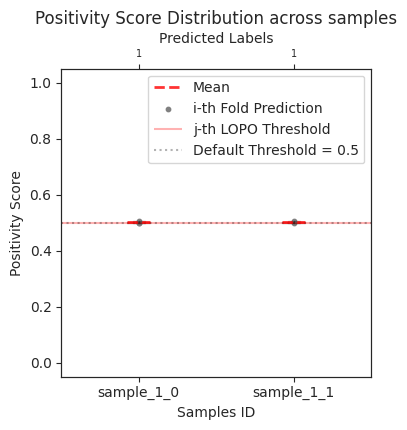

In [30]:
_, new_unlabelled_samples, samples_ids = load_data(new_data_folder_path, ext = extension, remove_columns = remove_columns)

seed_manager = SeedManager(starting_seed=starting_seed, LOPO_fold_idx=0)

test_samples_preds, best_thr = classify_new_samples(experiment_path = experiment_path,
                                                new_unlabelled_samples = new_unlabelled_samples,
                                                seed_manager = seed_manager,
                                                samples_ids = samples_ids)